# From pixels to protein degradation

**Name:** Oliwia Mruk
**Institute/Group:** CRUK SI/R30 (Madsen Lab)
**Date:** 18.11.2026

This workshop notebook was developed with assistance from **OpenAI Codex**, powered by **GPT-5**. Codex assisted with Python code debugging, data loading, quality control, and adaptation of the workflow used in the real experimental dataset from Serafini, Del Priore, Mruk, Puoti, et al. (2026).

## A three-hour microscopy image-analysis taster

**Biological question:** Can we measure tAKT abundance in individual cells,
compare degrader treatments, and examine whether cell-cycle state changes the
interpretation?

This notebook is a small, runnable version of the real analysis. We will use one
field to understand each step, then load the processed full experiment for QC
and plotting.

Optional Star Wars messages can be disabled without changing the analysis.

## Running this workshop in Google Colab

This is the browser version of the workshop. Nothing needs to be installed on your computer.

1. Choose **Runtime → Change runtime type**. Set **Runtime version** to **2026.07 (Python 3.12)**, leave the hardware accelerator as **None**, and save.
2. Run **Prepare Colab** below. Colab will restart once after installation.
3. Reconnect and run that cell once more; it should report that packages are ready.
4. Run **Download the workshop data**.
5. Continue through the notebook in order.

The first setup can take several minutes. Supplied masks remain available if a model download is temporarily unavailable.


In [ ]:
# PREPARE COLAB — run this first
# The runtime restarts once after installation. That is expected
import os
import sys
import subprocess
from pathlib import Path

try:
    import google.colab
except ImportError:
    raise RuntimeError(
        "This cell is for Google Colab. Use 01_WORKSHOP.ipynb locally."
    )

if sys.version_info[:2] != (3, 12):
    raise RuntimeError(
        f"This workshop needs Python 3.12, but this runtime uses "
        f"Python {sys.version_info.major}.{sys.version_info.minor}.\n\n"
        "Choose Runtime → Change runtime type → Runtime version → "
        "2026.07 (Python 3.12), save, reconnect, and rerun this cell."
    )

marker = Path("/content/.microscopy_workshop_packages_ready_py312_v2")
if not marker.exists():
    packages = [
        "numpy==1.26.4", "pandas<3", "scipy", "matplotlib", "seaborn",
        "scikit-image", "tifffile", "cellpose==3.1.1.2",
        "stardist==0.9.1", "csbdeep>=0.8,<1", "tensorflow==2.16.2",
        "opencv-python-headless<4.12", "imagecodecs<2025", "zarr<3",
        "ipywidgets",
    ]
    subprocess.check_call([
        sys.executable, "-m", "pip", "install", "--upgrade", *packages
    ])
    # StarDist uses TensorFlow. Remove Colab's unused JAX stack because its
    # ml_dtypes requirement conflicts with TensorFlow 2.16.2.
    subprocess.check_call([
        sys.executable, "-m", "pip", "uninstall", "-y", "jax", "jaxlib"
    ])
    marker.touch()
    print("Packages installed. Colab will restart now.")
    print("After it reconnects, run this cell once more, then continue.")
    os.kill(os.getpid(), 9)
else:
    print("Colab packages are ready. Continue to the data cell.")


Colab packages are ready. Continue to the data cell.


In [ ]:
# DOWNLOAD THE WORKSHOP DATA
DATA_URL = "https://raw.githubusercontent.com/olinm/microscopy-image-analysis-workshop/main/colab_workshop_data.zip"

import os
import urllib.request
import zipfile
from pathlib import Path

WORKSHOP_DIR = Path("/content/microscopy-workshop")
archive_path = Path("/content/colab_workshop_data.zip")
expected_file = WORKSHOP_DIR / "data/example_field/r02c02f01p01/Hoechst_ch1.tiff"

if not expected_file.exists():
    if DATA_URL.startswith("PASTE_"):
        print("The public data link has not been added yet.")
        print("For testing, upload colab_workshop_data.zip now.")
        from google.colab import files
        uploaded = files.upload()
        if "colab_workshop_data.zip" not in uploaded:
            raise FileNotFoundError("Please upload colab_workshop_data.zip")
        archive_path.write_bytes(uploaded["colab_workshop_data.zip"])
    else:
        print("Downloading workshop images and tables…")
        urllib.request.urlretrieve(DATA_URL, archive_path)

    WORKSHOP_DIR.mkdir(parents=True, exist_ok=True)
    with zipfile.ZipFile(archive_path) as archive:
        archive.extractall(WORKSHOP_DIR)

if not expected_file.exists():
    raise FileNotFoundError("The teaching image was not found after extraction.")

os.chdir(WORKSHOP_DIR)
print("Workshop data ready:", WORKSHOP_DIR)


Workshop data ready: /content/microscopy-workshop


In [ ]:
# Set this to False and all themed messages disappear
STAR_WARS_MODE = True

def report(scientific_message, themed_message=None):
    print(scientific_message)
    if STAR_WARS_MODE and themed_message:
        print(f"✨ {themed_message}")

report("Workshop settings loaded.", "The analysis awakens.")

Workshop settings loaded.
✨ The analysis awakens.


## Mission briefing: three channels, three jobs

- **ch1 — Hoechst:** segment nuclei with StarDist and estimate DNA content.
- **ch2 — HCSGreen:** segment whole cells with Cellpose.
- **ch3 — tAKT-A647:** measure the original tAKT signal inside each cell mask.

In [ ]:
from pathlib import Path
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from matplotlib.ticker import MultipleLocator
import ipywidgets as widgets
from IPython.display import display
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.spatial.distance import cdist
from skimage import io
from skimage.color import label2rgb
from skimage.measure import regionprops_table
from skimage.segmentation import find_boundaries

In [ ]:
# All three TIFFs and the supplied mask live in this folder
FIELD_NAME = "r02c02f01p01"
FIELD_DIR = Path("data/example_field") / FIELD_NAME

def find_one(channel):
    matches = sorted([p for p in FIELD_DIR.glob("*.tif*") if channel in p.name])
    if len(matches) != 1:
        raise FileNotFoundError(
            f"Expected exactly one {channel} TIFF in {FIELD_DIR}; found {len(matches)}."
        )
    return matches[0]

In [ ]:
# Load the three channels
hoechst_path = find_one("ch1")
hcsgreen_path = find_one("ch2")
takt_path = find_one("ch3")

hoechst = io.imread(hoechst_path)
hcsgreen = io.imread(hcsgreen_path)
takt = io.imread(takt_path)

In [ ]:
# Load the ready-made Cellpose and StarDist masks for the same field
supplied_cell_mask = io.imread(FIELD_DIR / "Cellpose_cell_mask.png")
supplied_nuclear_mask = io.imread(FIELD_DIR / "StarDist_nuclear_mask.tif")

assert (
    hoechst.shape == hcsgreen.shape == takt.shape
    == supplied_cell_mask.shape == supplied_nuclear_mask.shape
), "The images and masks must all describe the same field."
report(
    f"Loaded {FIELD_NAME} with shape {hoechst.shape}.",
    "All channels and masks report to the bridge.",
)

Loaded r02c02f01p01 with shape (2160, 2160).
✨ All channels and masks report to the bridge.


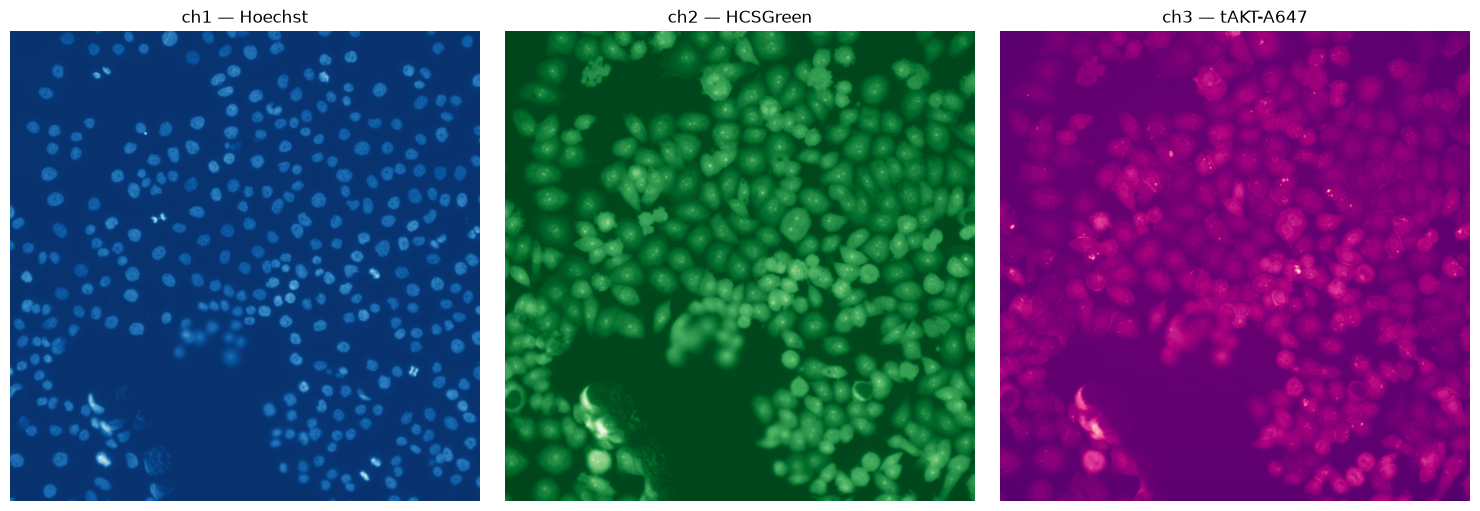

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, image, title, cmap in zip(
    axes,
    [hoechst, hcsgreen, takt],
    ["ch1 — Hoechst", "ch2 — HCSGreen", "ch3 — tAKT-A647"],
    ["Blues_r", "Greens_r", "RdPu_r"],
):
    ax.imshow(image, cmap=cmap)
    ax.set_title(title)
    ax.axis("off")
plt.tight_layout()
plt.show()

### Quick vote

1. We have three channels, but which one should we use to draw around the cells?
And which one should we actually measure?

2. Before we let the code run: **how many cells do you think are here?**

## A tiny shortcut

I’ve given you the finished mask for this image so we don’t spend the time watching Cellpose think. In a minute, we’ll zoom in and make our own.

![A mask acts like a cookie cutter](attachment:mask-cookie-cutter.svg)

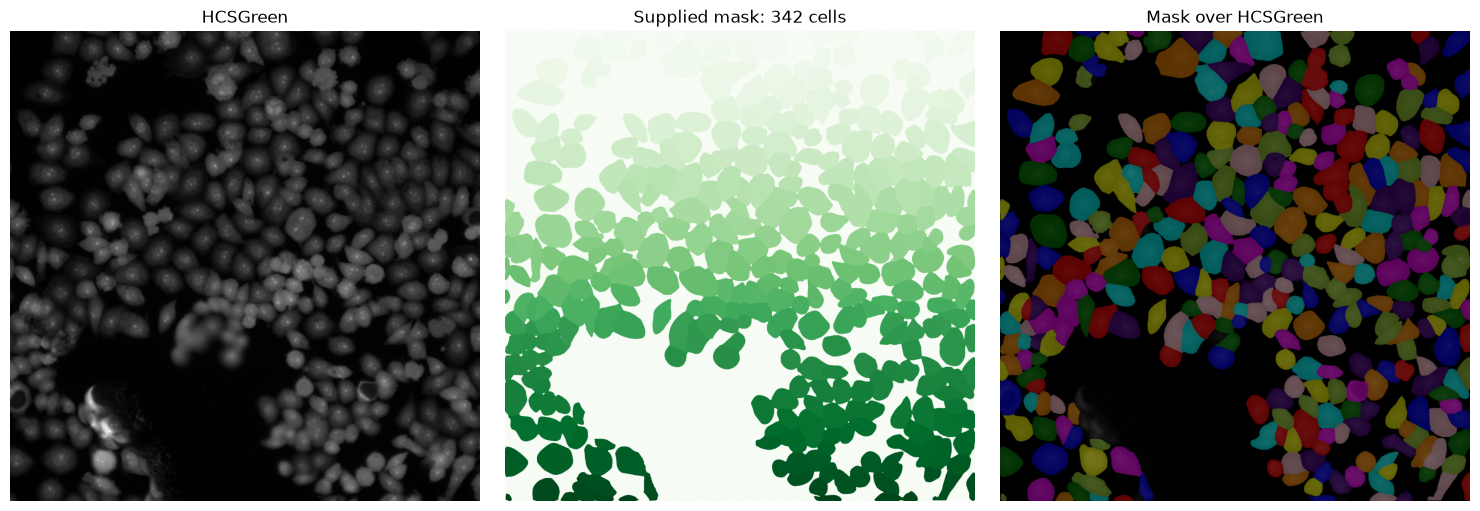

The supplied mask contains 342 labelled cells.
✨ These are the cells we're looking for—subject to QC.


In [ ]:
n_supplied_cells = int(supplied_cell_mask.max())
overlay = label2rgb(supplied_cell_mask, image=hcsgreen, bg_label=0, alpha=0.35)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
axes[0].imshow(hcsgreen, cmap="gray")
axes[0].set_title("HCSGreen")
axes[1].imshow(supplied_cell_mask, cmap="Greens")
axes[1].set_title(f"Supplied mask: {n_supplied_cells} cells")
axes[2].imshow(overlay)
axes[2].set_title("Mask over HCSGreen")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()
report(f"The supplied mask contains {n_supplied_cells} labelled cells.",
       "These are the cells we're looking for—subject to QC.")

## Now use the mask for something useful

The mask tells Python **where** each cell is. We then reach across to ch3 and ask:
what is the average tAKT signal inside each outline?

One important detail: we measure the original tAKT pixels. The image used to help
Cellpose see the cells is not the one that will be used for quantification.

In [ ]:
cell_table = pd.DataFrame(regionprops_table(
    supplied_cell_mask,
    intensity_image=takt,
    properties=("label", "area", "centroid", "mean_intensity"),
)).rename(columns={
    "label": "cell_ID",
    "centroid-1": "centroid_X",
    "centroid-0": "centroid_Y",
    "mean_intensity": "tAKT_mean_intensity",
})

display(cell_table.head())
print(f"Cells measured: {len(cell_table)}")
print(f"Median cell area: {cell_table['area'].median():,.0f} pixels")
print(f"Median tAKT intensity: {cell_table['tAKT_mean_intensity'].median():,.1f}")

,cell_ID,area,centroid_Y,centroid_X,tAKT_mean_intensity
0,1,14066.0,52.667425,258.620717,808.716906
1,2,2546.0,11.246269,410.440691,815.411233
2,3,5112.0,30.873631,545.040689,1048.526213
3,4,1637.0,11.073916,626.387294,799.983506
4,5,10064.0,44.039448,722.965521,1013.490163


Cells measured: 342
Median cell area: 7,810 pixels
Median tAKT intensity: 1,033.1


### Area QC should be visible, not just numerical

Very small masks may be debris or fragments. Very large masks may be merged
cells. The thresholds below update four linked views:

- the cell-area distribution
- a mask view showing **kept objects in green** and **removed objects in red**
- the same decision over the HCSGreen image
- the original tAKT distribution

Change one threshold, rerun the cell, and look at the objects that changed sides.
The aim is not to maximise the number of cells. It is to remove weird
objects without deleting real biology.

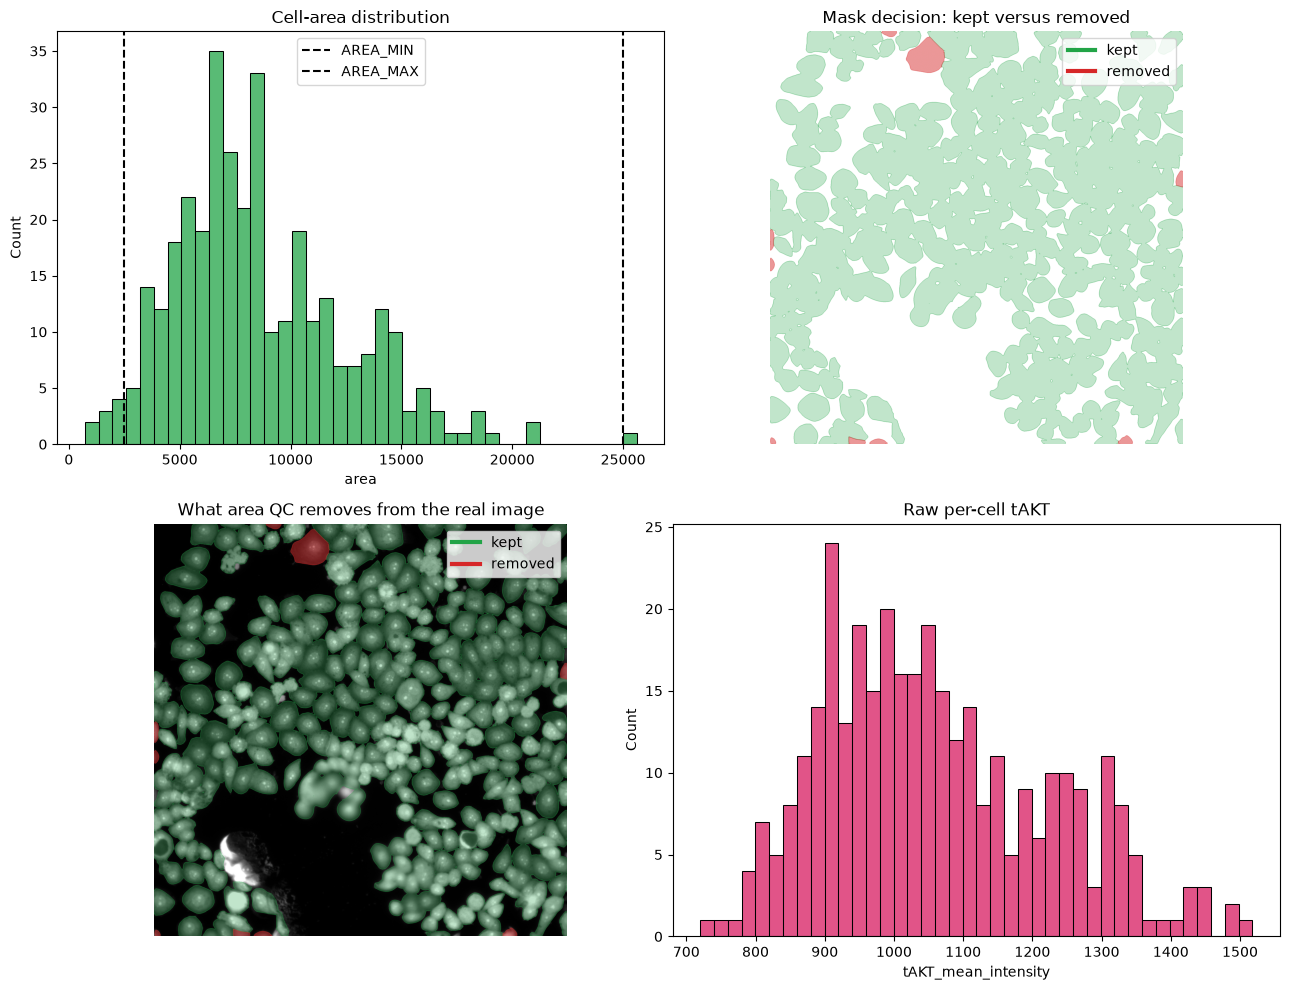

Kept: 333 cells
Removed: 9 objects


In [ ]:
# Try changing these and rerun this cell
AREA_MIN = 2500
AREA_MAX = 25000

passes_area = cell_table["area"].between(AREA_MIN, AREA_MAX)
kept_ids = cell_table.loc[passes_area, "cell_ID"].to_numpy()
removed_ids = cell_table.loc[~passes_area, "cell_ID"].to_numpy()

kept_pixels = np.isin(supplied_cell_mask, kept_ids)
removed_pixels = np.isin(supplied_cell_mask, removed_ids)

# Create clear—but not overly bold—green and red overlays
kept_overlay = np.zeros((*supplied_cell_mask.shape, 4), dtype=float)
kept_overlay[..., :3] = np.array([34, 164, 71]) / 255
kept_overlay[..., 3] = np.where(kept_pixels, 0.28, 0)
kept_overlay[find_boundaries(kept_pixels), 3] = 0.78

removed_overlay = np.zeros((*supplied_cell_mask.shape, 4), dtype=float)
removed_overlay[..., :3] = np.array([214, 39, 40]) / 255
removed_overlay[..., 3] = np.where(removed_pixels, 0.48, 0)
removed_overlay[find_boundaries(removed_pixels), 3] = 0.88

fig, axes = plt.subplots(2, 2, figsize=(13, 10))

sns.histplot(
    cell_table,
    x="area",
    bins=40,
    color="#22a447",
    ax=axes[0, 0],
)
axes[0, 0].axvline(
    AREA_MIN,
    color="black",
    linestyle="--",
    label="AREA_MIN",
)
axes[0, 0].axvline(
    AREA_MAX,
    color="black",
    linestyle="--",
    label="AREA_MAX",
)
axes[0, 0].set_title("Cell-area distribution")
axes[0, 0].legend()

# Show the mask decision on a white background
axes[0, 1].imshow(
    np.ones_like(supplied_cell_mask),
    cmap="gray",
    vmin=0,
    vmax=1,
)
axes[0, 1].imshow(kept_overlay)
axes[0, 1].imshow(removed_overlay)
axes[0, 1].plot(
    [],
    [],
    color="#22a447",
    linewidth=3,
    label="kept",
)
axes[0, 1].plot(
    [],
    [],
    color="#d62728",
    linewidth=3,
    label="removed",
)
axes[0, 1].set_title("Mask decision: kept versus removed")
axes[0, 1].legend(loc="upper right")

# Show the same decision over the real HCSGreen image
image_low, image_high = np.percentile(hcsgreen, [1, 99.5])

axes[1, 0].imshow(
    hcsgreen,
    cmap="gray",
    vmin=image_low,
    vmax=image_high,
)
axes[1, 0].imshow(kept_overlay)
axes[1, 0].imshow(removed_overlay)
axes[1, 0].plot(
    [],
    [],
    color="#22a447",
    linewidth=3,
    label="kept",
)
axes[1, 0].plot(
    [],
    [],
    color="#d62728",
    linewidth=3,
    label="removed",
)
axes[1, 0].set_title("What area QC removes from the real image")
axes[1, 0].legend(loc="upper right")

sns.histplot(
    cell_table,
    x="tAKT_mean_intensity",
    bins=40,
    color="#d81b60",
    ax=axes[1, 1],
)
axes[1, 1].set_title("Raw per-cell tAKT")

for ax in (axes[0, 1], axes[1, 0]):
    ax.axis("off")

plt.tight_layout()
plt.show()

print(f"Kept: {len(kept_ids)} cells")
print(f"Removed: {len(removed_ids)} objects")

### Optional QC: remove cells touching the image edge?

Cells touching the border may extend beyond the acquired image, meaning we cannot
see or measure the whole cell. This is particularly important when measuring cell
area, shape or total fluorescence.

I did not remove them in the original analysis because:

- the images are large, so edge cells are only a small fraction of the dataset
- the main measurement was mean tAKT intensity rather than total cell intensity
- the existing area filter already removes some unusually small fragments
- removing edge cells also discards otherwise usable measurements

For a small crop, morphology analysis or integrated-intensity measurement, removing
edge cells is usually more important. The cell below shows which cells would be
removed without changing the analysis automatically.

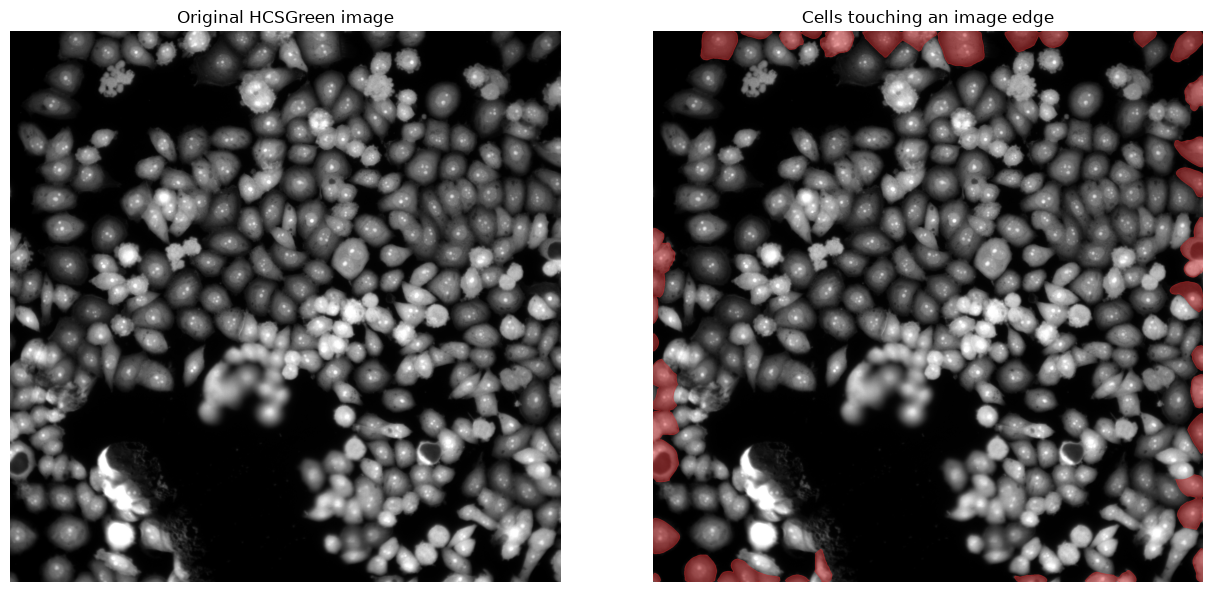

Total segmented cells: 342
Cells touching an edge: 46
Percentage touching an edge: 13.5%


In [ ]:
# Find labels touching the four edges of the image
border_ids = np.unique(
    np.concatenate([
        supplied_cell_mask[0, :],   # top edge
        supplied_cell_mask[-1, :],  # bottom edge
        supplied_cell_mask[:, 0],   # left edge
        supplied_cell_mask[:, -1],  # right edge
    ])
)

# Zero represents the background, not a cell.
border_ids = border_ids[border_ids != 0]

border_pixels = np.isin(supplied_cell_mask, border_ids)

# Red overlay showing cells that touch an image edge.
border_overlay = np.zeros((*supplied_cell_mask.shape, 4), dtype=float)
border_overlay[..., :3] = np.array([214, 39, 40]) / 255
border_overlay[..., 3] = np.where(border_pixels, 0.45, 0)
border_overlay[find_boundaries(border_pixels), 3] = 0.85

image_low, image_high = np.percentile(hcsgreen, [1, 99.5])

fig, axes = plt.subplots(1, 2, figsize=(13, 6))

axes[0].imshow(
    hcsgreen,
    cmap="gray",
    vmin=image_low,
    vmax=image_high,
)
axes[0].set_title("Original HCSGreen image")
axes[0].axis("off")

axes[1].imshow(
    hcsgreen,
    cmap="gray",
    vmin=image_low,
    vmax=image_high,
)
axes[1].imshow(border_overlay)
axes[1].set_title("Cells touching an image edge")
axes[1].axis("off")

plt.tight_layout()
plt.show()

print(f"Total segmented cells: {len(cell_table)}")
print(f"Cells touching an edge: {len(border_ids)}")
print(
    f"Percentage touching an edge: "
    f"{100 * len(border_ids) / len(cell_table):.1f}%"
)

In [ ]:
# If we decided we want to remove these edge cells, we can do so with the following:
#passes_edge_qc = ~cell_table["cell_ID"].isin(border_ids)
#passes_qc = passes_area & passes_edge_qc

## Right, now you do the segmentation

We’ll use one deliberately awkward crop: touching cells, something dim, and an
object escaping over the edge. The four numbers below just define the crop:
`top:bottom, left:right`.

How many cells and nuclei can you see before the models get involved?

### What do the crop numbers mean?

A digital image is a grid of pixels. This image has:

- **2,160 rows** running from top to bottom;
- **2,160 columns** running from left to right.

NumPy accesses an image using:

`image[rows, columns]`

Therefore:

- `TOP:BOTTOM` chooses the vertical range of rows;
- `LEFT:RIGHT` chooses the horizontal range of columns.

For example:

`image[200:700, 200:700]`

starts at row 200 and column 200. It extends down to—but does not include—row
700, and across to—but does not include—column 700.

The resulting crop is therefore:

- `700 - 200 = 500` pixels high;
- `700 - 200 = 500` pixels wide.

The red rectangle below shows those coordinates directly on the real image.

In [ ]:
# Change these four numbers to move or resize the crop.
TOP, BOTTOM = 1000, 1500
LEFT, RIGHT = 200, 700

hoechst_crop = hoechst[TOP:BOTTOM, LEFT:RIGHT]
hcsgreen_crop = hcsgreen[TOP:BOTTOM, LEFT:RIGHT]
takt_crop = takt[TOP:BOTTOM, LEFT:RIGHT]
reference_crop = supplied_cell_mask[TOP:BOTTOM, LEFT:RIGHT]

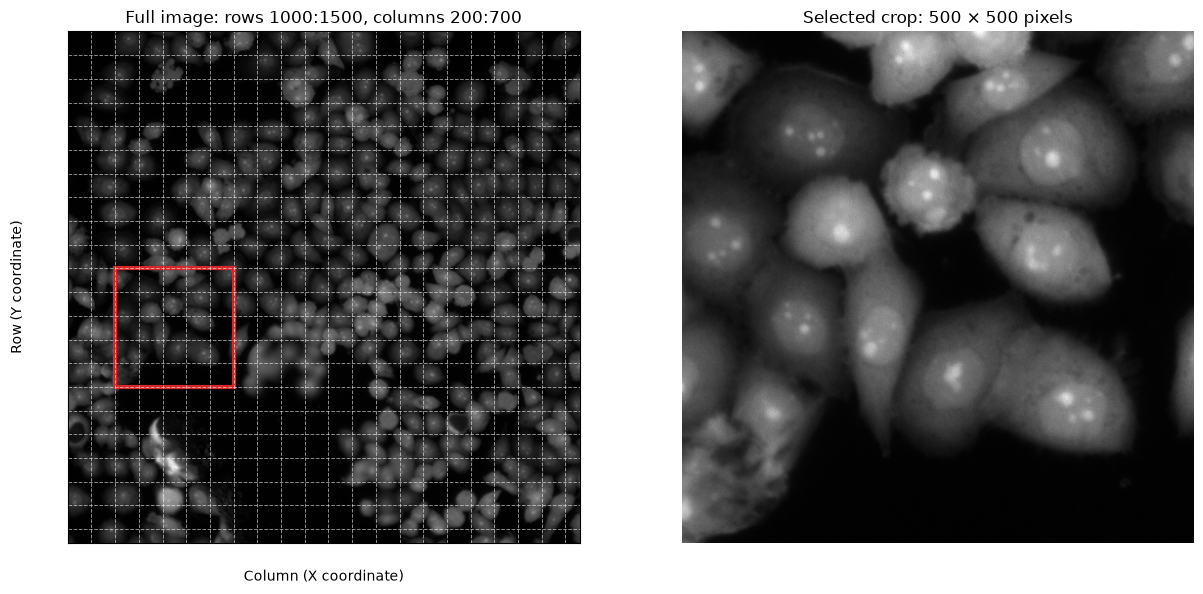

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 6))

# Show the full image and selected crop location
axes[0].imshow(hcsgreen, cmap="gray")

axes[0].add_patch(
    Rectangle(
        (LEFT, TOP),
        RIGHT - LEFT,
        BOTTOM - TOP,
        fill=False,
        edgecolor="#d62728",
        linewidth=3,
        label="Selected crop",
    )
)

# Add coordinate grid every 100 pixels
grid_spacing = 100

axes[0].xaxis.set_major_locator(MultipleLocator(grid_spacing))
axes[0].yaxis.set_major_locator(MultipleLocator(grid_spacing))

axes[0].grid(
    visible=True,
    color="white",
    linestyle="--",
    linewidth=0.7,
    alpha=0.55,
)

axes[0].tick_params(
    axis="both",
    colors="white",
    labelsize=8,
)

axes[0].set_xlabel("Column (X coordinate)")
axes[0].set_ylabel("Row (Y coordinate)")

axes[0].set_title(
    f"Full image: rows {TOP}:{BOTTOM}, "
    f"columns {LEFT}:{RIGHT}"
)

# Keep the coordinates visible on the full image
axes[0].axis("on")

# Show the resulting crop
axes[1].imshow(hcsgreen_crop, cmap="gray")

axes[1].set_title(
    f"Selected crop: "
    f"{hcsgreen_crop.shape[0]} × "
    f"{hcsgreen_crop.shape[1]} pixels"
)

axes[1].axis("off")

plt.tight_layout()
plt.show()

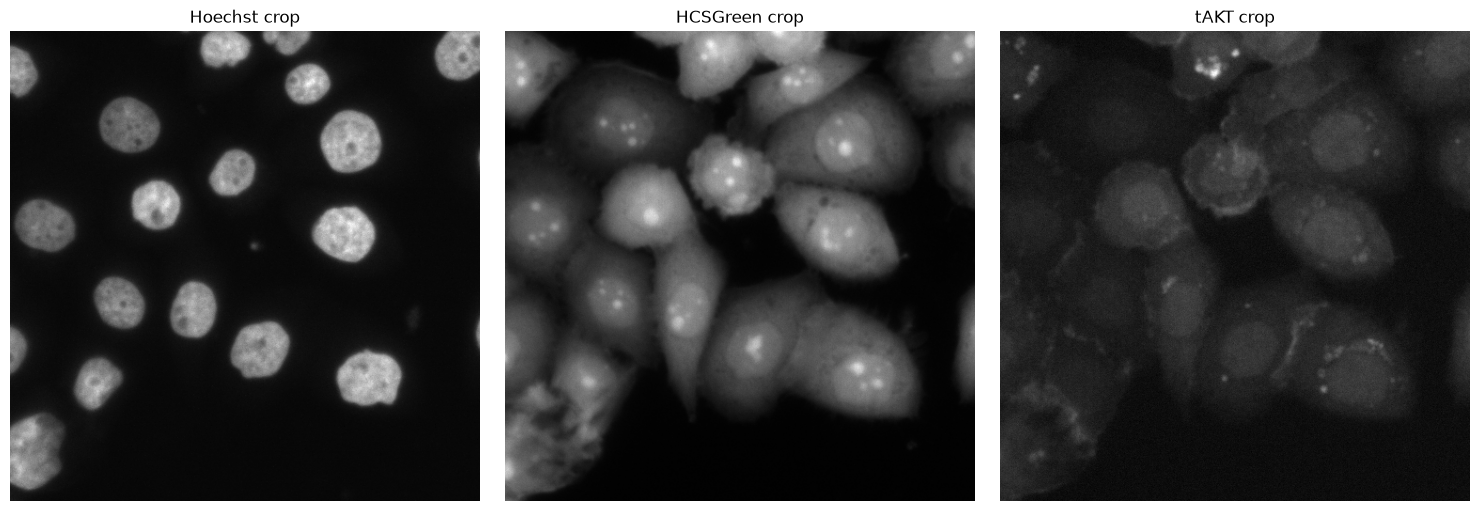

In [ ]:
# Rerun this after changing the crop above
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, image, title in zip(
    axes,
    [hoechst_crop, hcsgreen_crop, takt_crop],
    ["Hoechst crop", "HCSGreen crop", "tAKT crop"],
):
    ax.imshow(image, cmap="gray")
    ax.set_title(title)
    ax.axis("off")
plt.tight_layout()
plt.show()

### Run Cellpose on ch2

This notebook pins **Cellpose 3** because it matches the original analysis.
Loading the model and segmenting the image are separate steps:

- `model_type="cyto"` selects the pretrained cytoplasm model used in the pipeline;
- `gpu=False` keeps the workshop compatible with laptops without a configured GPU;
- changing the model requires rerunning the model-loading cell;
- changing thresholds only requires rerunning the parameter and evaluation cells.

Cellpose 3 also provides `cyto2`, `cyto3` and `nuclei`, but switching models is a
biological and technical choice, not a free accuracy upgrade. See the official
[Cellpose 3 model guide](https://cellpose.readthedocs.io/en/v3.1.1.1/models.html)
and [notebook documentation](https://cellpose.readthedocs.io/en/v3.1.1.1/notebook.html).

In [ ]:
from cellpose import models

CELLPOSE_MODEL_TYPE = "cyto"  # Matches the original analysis
USE_GPU = False               # Keep False unless this computer has a working GPU setup

cellpose_model = models.Cellpose(
    gpu=USE_GPU,
    model_type=CELLPOSE_MODEL_TYPE,
)
print(f"Cellpose model ready: {CELLPOSE_MODEL_TYPE!r}; GPU requested: {USE_GPU}")

Cellpose model ready: 'cyto'; GPU requested: False


### Cellpose settings you can actually test

These variables are not merely listed: the next cell passes every one of them
directly into `cellpose_model.eval(...)`.

- **`CELL_DIAMETER`**: expected cell diameter in pixels. `None` asks the Cellpose
  3 size model to estimate it. Too small can split cells; too large can merge or
  smooth away boundaries.
- **`FLOW_THRESHOLD`**: maximum tolerated disagreement between a proposed mask
  and the model's flow field. Lower is stricter; higher keeps more questionable
  shapes.
- **`CELLPROB_THRESHOLD`**: how much cell evidence a pixel needs. Lower values
  usually find more or larger objects, including dim ones and possible false
  positives. Higher values are more selective.
- **`MIN_CELL_SIZE`**: masks smaller than this many pixels are discarded. This
  acts during segmentation, unlike the later biological area-QC thresholds.
- **`NORMALIZE_INPUT`**: rescales image intensity before inference. Keep it on
  here because raw microscopy intensity ranges vary.

Official references: [Cellpose 3 settings](https://cellpose.readthedocs.io/en/v3.1.1.1/settings.html)
and the full [`eval` API](https://cellpose.readthedocs.io/en/v3.1.1.1/api.html#cellpose.models.Cellpose.eval).

In [ ]:
# Change ONE setting first, then rerun this and the next two cells
CELL_DIAMETER = None
FLOW_THRESHOLD = 0.4
CELLPROB_THRESHOLD = 0.0
MIN_CELL_SIZE = 15
NORMALIZE_INPUT = True

print({
    "diameter": CELL_DIAMETER,
    "flow_threshold": FLOW_THRESHOLD,
    "cellprob_threshold": CELLPROB_THRESHOLD,
    "min_size": MIN_CELL_SIZE,
    "normalize": NORMALIZE_INPUT,
})

{'diameter': None, 'flow_threshold': 0.4, 'cellprob_threshold': 0.0, 'min_size': 15, 'normalize': True}


### What `eval` receives and returns

**Inputs**

- `hcsgreen_crop`: the 2D image sent to Cellpose.
- `channels=[0, 0]`: use one grayscale segmentation channel and no separate
  nuclear channel.
- the five settings from the cell above.

**Outputs**

- `cellpose_mask`: labelled image; 0 is background and 1, 2, 3… are cells.
- `flows`: intermediate direction and cell-probability predictions used to
  construct masks. They are useful for deeper troubleshooting, but are not our
  biological measurement.
- `styles`: a compact description of the image learned by Cellpose 3. Its size
  model can use this to estimate diameter.
- `diameter`: the estimated or supplied object diameter used for this run.

The mask is the output carried into measurement. The original tAKT image remains
the source of intensity values.

In [ ]:
cellpose_mask, flows, styles, diameter = cellpose_model.eval(
    hcsgreen_crop,
    diameter=CELL_DIAMETER,
    channels=[0, 0],
    flow_threshold=FLOW_THRESHOLD,
    cellprob_threshold=CELLPROB_THRESHOLD,
    min_size=MIN_CELL_SIZE,
    normalize=NORMALIZE_INPUT,
)

print(f"Cellpose found {int(cellpose_mask.max())} cells.")
print(f"Diameter used/estimated: {float(np.asarray(diameter).squeeze()):.1f} pixels")
print(f"Mask shape: {cellpose_mask.shape}")

/usr/local/lib/python3.12/dist-packages/cellpose/dynamics.py:760: UserWarning: Sparse invariant checks are implicitly disabled. Memory errors (e.g. SEGFAULT) will occur when operating on a sparse tensor which violates the invariants, but checks incur performance overhead. To silence this warning, explicitly opt in or out. See `torch.sparse.check_sparse_tensor_invariants.__doc__` for guidance.  (Triggered internally at /pytorch/aten/src/ATen/Context.cpp:760.)
  coo = torch.sparse_coo_tensor(pt, torch.ones(pt.shape[1], device=pt.device, dtype=torch.int),


Cellpose found 22 cells.
Diameter used/estimated: 91.9 pixels
Mask shape: (500, 500)


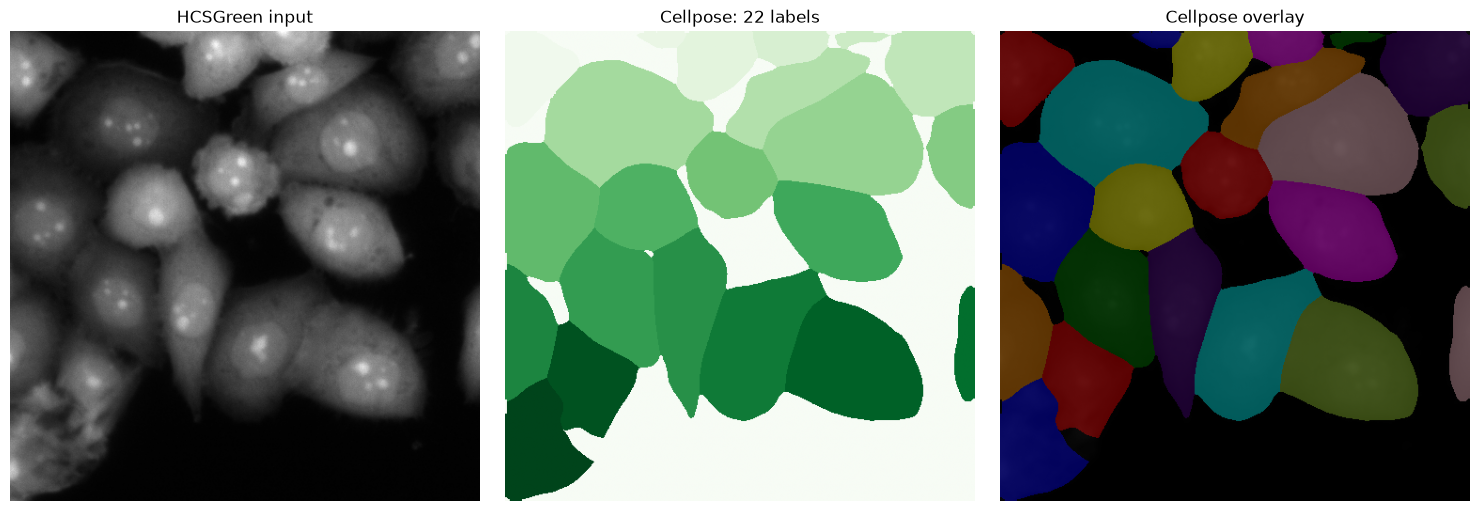

In [ ]:
# What changed? Did it actually get better?
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
axes[0].imshow(hcsgreen_crop, cmap="gray")
axes[0].set_title("HCSGreen input")
axes[1].imshow(cellpose_mask, cmap="Greens")
axes[1].set_title(f"Cellpose: {int(cellpose_mask.max())} labels")
axes[2].imshow(label2rgb(cellpose_mask, image=hcsgreen_crop, bg_label=0, alpha=0.35))
axes[2].set_title("Cellpose overlay")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

### Run StarDist on ch1

StarDist segments nuclei. Its count is not expected to equal the Cellpose count
exactly because the two models identify different biological objects.

StarDist predicts an object probability and distances to a possible nuclear
boundary at each pixel. Two thresholds then affect the final instances:

- **probability threshold**: only sufficiently confident object candidates can
  become nuclei. Raising it usually removes dim or uncertain nuclei; lowering it
  can recover them but may add false positives.
- **NMS threshold**: non-maximum suppression decides when overlapping candidates
  represent the same nucleus. Lower values suppress overlapping candidates more
  aggressively; higher values allow more overlap.

Read the official StarDist explanation of
[probability and NMS thresholds](https://github.com/stardist/stardist-docs/blob/main/docs/faq.md#what-are-the-probability-and-overlapnms-thresholds-how-do-i-select-good-values).

In [ ]:
from csbdeep.utils import normalize
from stardist.models import StarDist2D

stardist_model = StarDist2D.from_pretrained("2D_versatile_fluo")
print("StarDist is ready.")

Found model '2D_versatile_fluo' for 'StarDist2D'.
5320433/5320433 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Loading network weights from 'weights_best.h5'.
Loading thresholds from 'thresholds.json'.
Using default values: prob_thresh=0.479071, nms_thresh=0.3.
StarDist is ready.


In [ ]:
# Change one setting first
# Try probability values 0.30, 0.50 and 0.70
PROBABILITY_THRESHOLD = 0.50

# Try NMS values 0.20, 0.40 and 0.60 if touching nuclei are merged or duplicated
NMS_THRESHOLD = 0.40

# Percentiles used to normalise the image for StarDist inference
NORMALIZE_LOW = 1
NORMALIZE_HIGH = 99.8

In [ ]:
nuclear_mask, stardist_details = stardist_model.predict_instances(
    normalize(hoechst_crop, NORMALIZE_LOW, NORMALIZE_HIGH, axis=None),
    prob_thresh=PROBABILITY_THRESHOLD,
    nms_thresh=NMS_THRESHOLD,
)

print(f"StarDist found {int(nuclear_mask.max())} nuclei.")

StarDist found 20 nuclei.


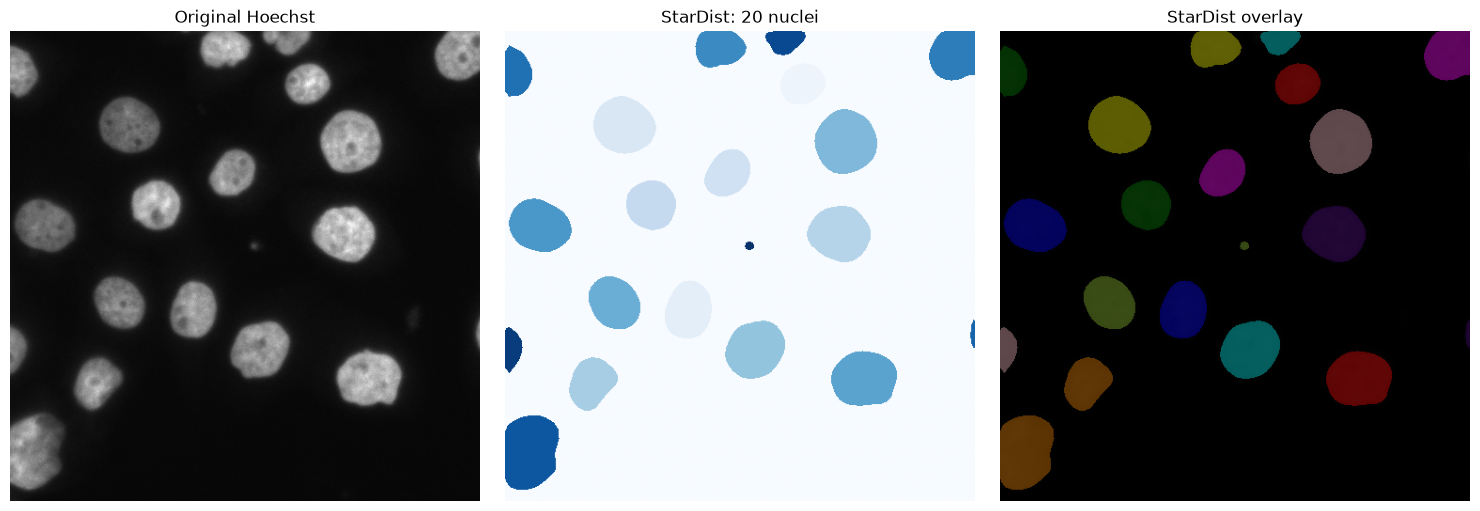

In [ ]:
# Inspect the result before deciding that the count is 'correct'
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
axes[0].imshow(hoechst_crop, cmap="gray")
axes[0].set_title("Original Hoechst")
axes[1].imshow(nuclear_mask, cmap="Blues")
axes[1].set_title(f"StarDist: {int(nuclear_mask.max())} nuclei")
axes[2].imshow(label2rgb(nuclear_mask, image=hoechst_crop, bg_label=0, alpha=0.35))
axes[2].set_title("StarDist overlay")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

### See the probability threshold change the actual nuclei

This comparison runs the same crop at three probability thresholds. Look for a
dim nucleus that appears at 0.30 but disappears at 0.70. Then check whether it is
a genuine nucleus or noise. A higher count is not automatically a better mask.

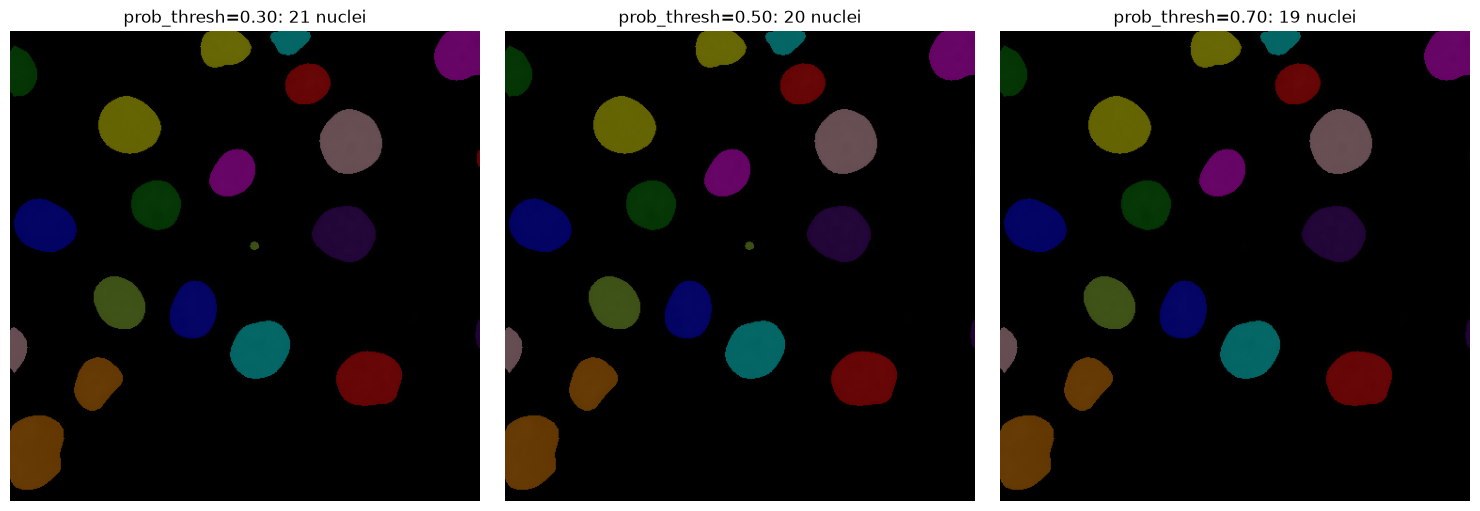

In [ ]:
thresholds_to_compare = [0.30, 0.50, 0.70]
normalised_hoechst = normalize(
    hoechst_crop, NORMALIZE_LOW, NORMALIZE_HIGH, axis=None
)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, threshold in zip(axes, thresholds_to_compare):
    comparison_mask, _ = stardist_model.predict_instances(
        normalised_hoechst,
        prob_thresh=threshold,
        nms_thresh=NMS_THRESHOLD,
    )
    ax.imshow(label2rgb(
        comparison_mask,
        image=hoechst_crop,
        bg_label=0,
        alpha=0.38,
    ))
    ax.set_title(f"prob_thresh={threshold:.2f}: {comparison_mask.max()} nuclei")
    ax.axis("off")

plt.tight_layout()
plt.show()

## Measure nuclei and integrated Hoechst

StarDist sees a normalised image, but the measurements come from the original
Hoechst pixels. Integrated Hoechst is nuclear area multiplied by mean intensity
and is used as a proxy for DNA content.

In [ ]:
if nuclear_mask.max() > 0:
    nucleus_table = pd.DataFrame(regionprops_table(
        nuclear_mask,
        intensity_image=hoechst_crop,
        properties=("label", "area", "centroid", "mean_intensity"),
    )).rename(columns={
        "label": "nucleus_ID",
        "area": "nuclear_area",
        "centroid-1": "centroid_X",
        "centroid-0": "centroid_Y",
        "mean_intensity": "Hoechst_mean_intensity",
    })
    nucleus_table["Hoechst_integrated_intensity"] = (
        nucleus_table["nuclear_area"] * nucleus_table["Hoechst_mean_intensity"]
    )
    display(nucleus_table.head())
else:
    nucleus_table = pd.DataFrame()
    print("No StarDist nuclei are available yet.")

,nucleus_ID,nuclear_area,centroid_Y,centroid_X,Hoechst_mean_intensity,Hoechst_integrated_intensity
0,1,1648.0,55.934466,316.034587,2363.245752,3894629.0
1,2,2429.0,296.765747,194.716344,2059.782215,5003211.0
2,3,3126.0,100.073576,126.161228,1418.346129,4433750.0
3,4,1864.0,150.958155,236.631438,2075.096567,3867980.0
4,5,2205.0,184.678458,155.105215,2444.545125,5390222.0


## Pair each cell with a nucleus

Now the two masks need to meet. We connect the closest available cell and nucleus,
then take both out of the dating pool so neither can be matched twice.

That slightly odd-sounding rule is the same greedy one-to-one matching used in
the full R analysis.

![Centroid matching](attachment:centroid-matching.svg)

In [ ]:
def greedy_centroid_match(cells, nuclei, max_distance=75):
    result = cells.copy()
    result["nucleus_ID"] = pd.NA
    result["match_distance"] = np.nan
    result["Hoechst_integrated_intensity"] = np.nan
    if cells.empty or nuclei.empty:
        return result

    distances = cdist(
        cells[["centroid_X", "centroid_Y"]],
        nuclei[["centroid_X", "centroid_Y"]],
    )
    candidates = np.argwhere(distances <= max_distance)
    candidates = sorted(candidates, key=lambda ij: distances[tuple(ij)])
    used_cells, used_nuclei = set(), set()
    for cell_i, nucleus_i in candidates:
        if cell_i in used_cells or nucleus_i in used_nuclei:
            continue
        used_cells.add(cell_i)
        used_nuclei.add(nucleus_i)
        result.loc[result.index[cell_i], "nucleus_ID"] = int(nuclei.iloc[nucleus_i]["nucleus_ID"])
        result.loc[result.index[cell_i], "match_distance"] = distances[cell_i, nucleus_i]
        result.loc[result.index[cell_i], "Hoechst_integrated_intensity"] = nuclei.iloc[nucleus_i]["Hoechst_integrated_intensity"]
    return result

In [ ]:
# Measure the Cellpose cells before trying to match them
crop_cells = pd.DataFrame(regionprops_table(
    cellpose_mask,
    intensity_image=takt_crop,
    properties=("label", "area", "centroid", "mean_intensity"),
)).rename(columns={
    "label": "cell_ID", "centroid-1": "centroid_X", "centroid-0": "centroid_Y",
    "mean_intensity": "tAKT_mean_intensity",
})

In [ ]:
# Try 25, 50, 75 and 100 pixels. More matches are not always better
MAX_MATCH_DISTANCE = 75

matched_crop = greedy_centroid_match(crop_cells, nucleus_table, MAX_MATCH_DISTANCE)
display(matched_crop.head())
print(f"Matched {matched_crop['nucleus_ID'].notna().sum()} of {len(matched_crop)} cells.")

,cell_ID,area,centroid_Y,centroid_X,tAKT_mean_intensity,nucleus_ID,match_distance,Hoechst_integrated_intensity
0,1,5480.0,44.669343,29.857664,979.503832,15,17.767784,2447898.0
1,2,735.0,7.523810,168.108844,1139.142857,<NA>,NaN,NaN
2,3,5145.0,32.977843,221.600000,1250.736054,13,16.174469,4179492.0
3,4,2479.0,15.631706,302.851150,1285.251311,18,7.640994,1561384.0
4,5,672.0,6.997024,375.318452,821.220238,<NA>,NaN,NaN


Matched 19 of 22 cells.


### What does 75 pixels mean on this image?

The left panel draws every accepted cell–nucleus connection on the crop. Cells
without an accepted nucleus are marked with a red ×. The right panel shows each
cell's nearest nuclear distance before one-to-one competition is resolved.

Increase `MAX_MATCH_DISTANCE` and more distant pairs become eligible. That may
recover a real offset nucleus, but it can also attach a cell to its neighbour's
nucleus. Judge the lines, not only the matched count.

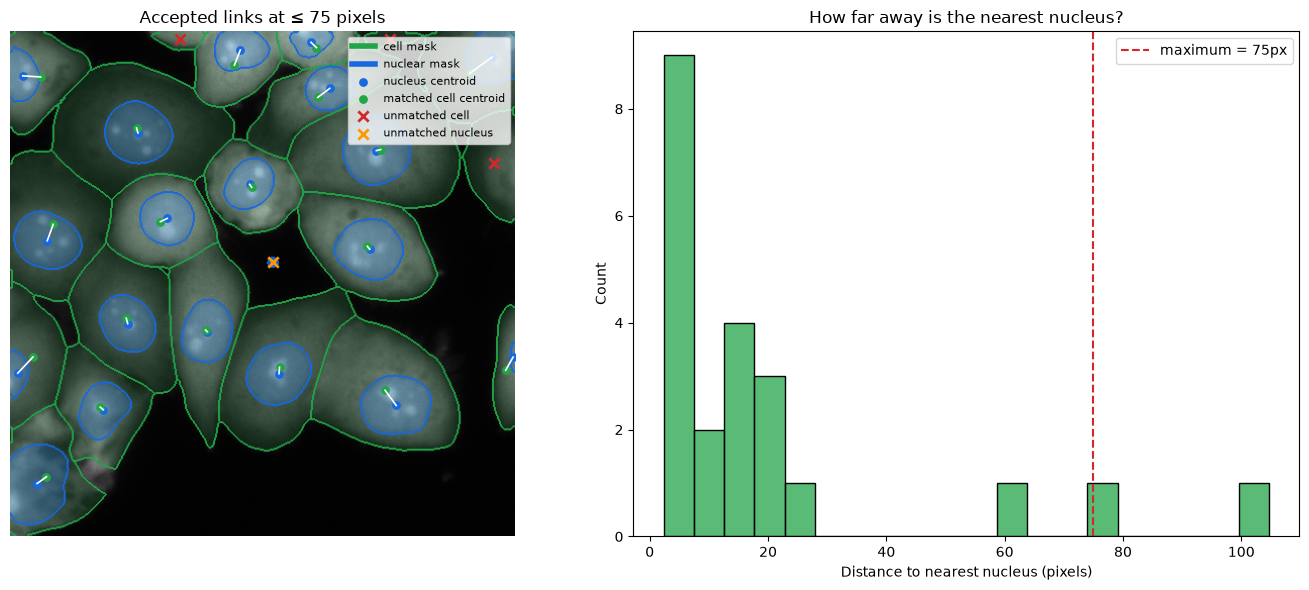

Unmatched cells: 3
Unmatched nuclei: 1


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

axes[0].imshow(hcsgreen_crop, cmap="gray")

# Overlay both segmentation results using the workshop colour scheme:
# whole-cell/cytoplasm masks are green and nuclear masks are blue
cell_overlay = np.zeros((*cellpose_mask.shape, 4), dtype=float)
cell_overlay[..., :3] = np.array([34, 164, 71]) / 255
cell_overlay[..., 3] = np.where(cellpose_mask > 0, 0.16, 0.0)
cell_overlay[find_boundaries(cellpose_mask), 3] = 0.95
axes[0].imshow(cell_overlay)

nucleus_overlay = np.zeros((*nuclear_mask.shape, 4), dtype=float)
nucleus_overlay[..., :3] = np.array([23, 105, 224]) / 255
nucleus_overlay[..., 3] = np.where(nuclear_mask > 0, 0.26, 0.0)
nucleus_overlay[find_boundaries(nuclear_mask), 3] = 0.95
axes[0].imshow(nucleus_overlay)

axes[0].plot(
    [],
    [],
    color="#22a447",
    linewidth=4,
    label="cell mask",
)
axes[0].plot(
    [],
    [],
    color="#1769e0",
    linewidth=4,
    label="nuclear mask",
)

# Plot all nuclear centroids
axes[0].scatter(
    nucleus_table["centroid_X"],
    nucleus_table["centroid_Y"],
    c="#1769e0",
    s=28,
    label="nucleus centroid",
)

# Add nuclear coordinates to the matched-cell table
matched_for_plot = matched_crop.merge(
    nucleus_table[
        ["nucleus_ID", "centroid_X", "centroid_Y"]
    ],
    on="nucleus_ID",
    how="left",
    suffixes=("_cell", "_nucleus"),
)

# Draw a line between each accepted cell–nucleus pair
for _, row in matched_for_plot.dropna(
    subset=["centroid_X_nucleus"]
).iterrows():

    axes[0].plot(
        [
            row["centroid_X_cell"],
            row["centroid_X_nucleus"],
        ],
        [
            row["centroid_Y_cell"],
            row["centroid_Y_nucleus"],
        ],
        color="white",
        linewidth=1.2,
    )

# Identify matched and unmatched cells
matched_rows = matched_crop["nucleus_ID"].notna()

axes[0].scatter(
    matched_crop.loc[matched_rows, "centroid_X"],
    matched_crop.loc[matched_rows, "centroid_Y"],
    c="#22a447",
    s=28,
    label="matched cell centroid",
)

axes[0].scatter(
    matched_crop.loc[~matched_rows, "centroid_X"],
    matched_crop.loc[~matched_rows, "centroid_Y"],
    c="#d62728",
    marker="x",
    s=55,
    linewidth=2,
    label="unmatched cell",
)

# Identify nuclei that were not assigned to any Cellpose cell
matched_nucleus_ids = set(
    matched_crop["nucleus_ID"]
    .dropna()
    .astype(int)
)

unmatched_nuclei = nucleus_table.loc[
    ~nucleus_table["nucleus_ID"].isin(matched_nucleus_ids)
]

# This includes small StarDist detections, but does not remove them
axes[0].scatter(
    unmatched_nuclei["centroid_X"],
    unmatched_nuclei["centroid_Y"],
    c="#ff9800",
    marker="x",
    s=55,
    linewidth=2,
    label="unmatched nucleus",
)

axes[0].set_title(
    f"Accepted links at ≤ {MAX_MATCH_DISTANCE} pixels"
)
axes[0].legend(loc="upper right", fontsize=8)
axes[0].axis("off")


# Plot the distance from each cell to its nearest nucleus
if len(crop_cells) and len(nucleus_table):

    all_distances = cdist(
        crop_cells[
            ["centroid_X", "centroid_Y"]
        ],
        nucleus_table[
            ["centroid_X", "centroid_Y"]
        ],
    )

    nearest_distance = all_distances.min(axis=1)

    sns.histplot(
        nearest_distance,
        bins=20,
        color="#22a447",
        ax=axes[1],
    )

    axes[1].axvline(
        MAX_MATCH_DISTANCE,
        color="#d62728",
        linestyle="--",
        label=f"maximum = {MAX_MATCH_DISTANCE}px",
    )

    axes[1].set_xlabel(
        "Distance to nearest nucleus (pixels)"
    )
    axes[1].set_title(
        "How far away is the nearest nucleus?"
    )
    axes[1].legend()

else:
    axes[1].text(
        0.5,
        0.5,
        "No centroids available",
        ha="center",
        va="center",
    )
    axes[1].axis("off")

plt.tight_layout()
plt.show()

print(
    f"Unmatched cells: "
    f"{(~matched_rows).sum()}"
)

print(
    f"Unmatched nuclei: "
    f"{len(unmatched_nuclei)}"
)

## Interactive QC in the browser

Printing images one by one is useful while learning, but slow for troubleshooting. The controls below switch channels, show or hide masks, change opacity and zoom without leaving Colab.

This replaces napari in the browser edition. napari remains better when masks need to be drawn or edited manually.


In [ ]:
# Browser-friendly interactive QC (replaces napari in Colab)
channel_images = {
    "Hoechst — nuclei": (hoechst_crop, "Blues_r"),
    "HCSGreen — cells": (hcsgreen_crop, "Greens_r"),
    "tAKT-A647": (takt_crop, "magma"),
}
cell_colour = np.array([34, 164, 71]) / 255
nucleus_colour = np.array([23, 105, 224]) / 255

def show_interactive_qc(
    channel="Hoechst — nuclei", show_supplied_cells=True,
    show_cellpose_result=False, show_stardist_nuclei=True,
    show_centroids=True, mask_opacity=0.28,
    centre_x=250, centre_y=250, view_width=500,
):
    image, colourmap = channel_images[channel]
    half = max(50, view_width // 2)
    x0, x1 = max(0, centre_x-half), min(image.shape[1], centre_x+half)
    y0, y1 = max(0, centre_y-half), min(image.shape[0], centre_y+half)
    fig, ax = plt.subplots(figsize=(8, 8))
    ax.imshow(image[y0:y1, x0:x1], cmap=colourmap)

    def add_mask(mask, colour):
        section = mask[y0:y1, x0:x1]
        visible = section > 0
        overlay = np.zeros((*visible.shape, 4), dtype=float)
        overlay[..., :3] = colour
        overlay[..., 3] = np.where(visible, mask_opacity, 0.0)
        overlay[find_boundaries(section), 3] = 0.95
        ax.imshow(overlay)

    if show_supplied_cells:
        add_mask(reference_crop, cell_colour)
    if show_cellpose_result:
        add_mask(cellpose_mask, cell_colour)
    if show_stardist_nuclei and nuclear_mask.max() > 0:
        add_mask(nuclear_mask, nucleus_colour)

    if show_centroids:
        nuclei = nucleus_table[
            nucleus_table["centroid_X"].between(x0, x1)
            & nucleus_table["centroid_Y"].between(y0, y1)
        ]
        cells = crop_cells[
            crop_cells["centroid_X"].between(x0, x1)
            & crop_cells["centroid_Y"].between(y0, y1)
        ]
        ax.scatter(nuclei["centroid_X"]-x0, nuclei["centroid_Y"]-y0,
                   c="#1769e0", s=26, label="nucleus centroid")
        ax.scatter(cells["centroid_X"]-x0, cells["centroid_Y"]-y0,
                   c="#22a447", s=26, label="cell centroid")
        ax.legend(loc="upper right", fontsize=8)
    ax.set_title(f"Interactive QC — {channel}")
    ax.axis("off")
    plt.show()

interactive_qc = widgets.interactive(
    show_interactive_qc,
    channel=widgets.Dropdown(options=list(channel_images), description="Channel"),
    show_supplied_cells=widgets.Checkbox(value=True, description="Supplied cells"),
    show_cellpose_result=widgets.Checkbox(value=False, description="Cellpose result"),
    show_stardist_nuclei=widgets.Checkbox(value=True, description="StarDist nuclei"),
    show_centroids=widgets.Checkbox(value=True, description="Centroids"),
    mask_opacity=widgets.FloatSlider(value=0.28, min=0, max=0.8, step=0.05, description="Opacity"),
    centre_x=widgets.IntSlider(value=250, min=0, max=500, step=10, description="Centre X"),
    centre_y=widgets.IntSlider(value=250, min=0, max=500, step=10, description="Centre Y"),
    view_width=widgets.IntSlider(value=500, min=100, max=500, step=50, description="Width"),
)
display(interactive_qc)
report("The arrays are now available as interactive browser layers.",
       "Your eyes can deceive you—check the mask.")


interactive(children=(Dropdown(description='Channel', options=('Hoechst — nuclei', 'HCSGreen — cells', 'tAKT-A…

The arrays are now available as interactive browser layers.
✨ Your eyes can deceive you—check the mask.


### Find something dodgy

Find one merged, split, dim, or edge object. Which Cellpose or StarDist setting
might help? Change one thing, rerun it, and see whether you fixed the problem or
simply created a more interesting problem somewhere else.

## Lock in the area-QC decision

You inspected the removed objects earlier. We now store that decision in the
table so the same thresholds can be applied consistently to the full dataset.

In [ ]:
cell_table["passes_area_qc"] = cell_table["area"].between(AREA_MIN, AREA_MAX)
qc_summary = cell_table["passes_area_qc"].value_counts().rename(index={True: "Pass", False: "Removed"})
display(qc_summary.to_frame("cells"))

removed_objects = cell_table.loc[
    ~cell_table["passes_area_qc"],
    ["cell_ID", "area", "tAKT_mean_intensity"],
].sort_values("area")
display(removed_objects)
report(f"Area QC removed {len(removed_objects)} objects.", "The phantom debris has been identified.")

,cells
passes_area_qc,
Pass,333
Removed,9


,cell_ID,area,tAKT_mean_intensity
339,340,719.0,744.130737
201,202,1220.0,781.398361
3,4,1637.0,799.983506
340,341,1901.0,783.740137
172,173,1919.0,940.984367
337,338,2300.0,908.256522
118,119,2365.0,918.781818
335,336,2382.0,1062.292191
16,17,25621.0,831.751103


Area QC removed 9 objects.
✨ The phantom debris has been identified.


## One field down. Quite a few to go.

We have just walked through one field slowly. The full table comes from repeating
those same segmentation, measurement, and matching steps over every field.

Thankfully, we prepared that part earlier.

In [ ]:
from pathlib import Path
import pandas as pd

cell_data_dir = Path(
    "data/03-12-2024_real_experiment/cell_properties"
)

cell_files = sorted(
    path for path in cell_data_dir.glob("*_cell_properties.csv")
    if not path.name.startswith("._")
)

if not cell_files:
    raise FileNotFoundError(
        f"No cell-property CSV files found in: {cell_data_dir}"
    )

frames = []

for path in cell_files:
    # Example: r02c02f01p01_cell_properties.csv
    field_id = path.name.removesuffix("_cell_properties.csv")

    frame = pd.read_csv(path)
    frame["field_id"] = field_id
    frame["well_id"] = field_id[:6]       # r02c02
    frame["field"] = field_id[6:9]        # f01
    frame["source_file"] = path.name

    frames.append(frame)

full_data = pd.concat(frames, ignore_index=True)

# Keep the column name expected by the later workshop analysis
full_data = full_data.rename(
    columns={"AKT_mean_intensity": "tAKT_mean_intensity"}
)

# Assign the experimental treatment from the well position
well_combinations = {
    "r02c02": "DMSO", "r02c05": "DMSO",
    "r03c02": "SMM377, 1uM", "r04c02": "SMM377, 1uM",
    "r05c02": "SMM377, 100nM", "r06c02": "SMM377, 100nM",
    "r02c03": "SMM388, 1uM", "r03c03": "SMM388, 1uM",
    "r04c03": "SMM388, 100nM", "r05c03": "SMM388, 100nM",
    "r06c03": "SMM389, 1uM", "r07c03": "SMM389, 1uM",
    "r02c04": "SMM389, 100nM", "r03c04": "SMM389, 100nM",
    "r04c04": "INY-03-041, 100nM", "r05c04": "INY-03-041, 100nM",
    "r06c04": "INY-05-040, 100nM", "r07c04": "INY-05-040, 100nM",
    "r03c05": "MS15, 100nM", "r04c05": "MS15, 100nM",
    "r05c05": "ARQ-092, 1uM", "r06c05": "ARQ-092, 1uM",
    "r07c02": "DMSO, Ab-free", "r07c05": "DMSO, Ab-free",
}

order = [
    "DMSO", "SMM377, 1uM", "SMM377, 100nM",
    "SMM388, 1uM", "SMM388, 100nM", "SMM389, 1uM",
    "SMM389, 100nM", "INY-03-041, 100nM",
    "INY-05-040, 100nM", "MS15, 100nM", "ARQ-092, 1uM",
    "DMSO, Ab-free",
]

color_palette = {
    "DMSO": "red", "SMM377, 1uM": "orange",
    "SMM377, 100nM": "orange", "SMM388, 1uM": "orange",
    "SMM388, 100nM": "orange", "SMM389, 1uM": "orange",
    "SMM389, 100nM": "orange", "INY-03-041, 100nM": "green",
    "INY-05-040, 100nM": "green", "MS15, 100nM": "green",
    "ARQ-092, 1uM": "yellow", "DMSO, Ab-free": "red",
}

full_data["treatment"] = full_data["well_id"].map(well_combinations)
unmapped_wells = sorted(
    full_data.loc[full_data["treatment"].isna(), "well_id"].unique()
)
if unmapped_wells:
    raise ValueError(f"No treatment mapping supplied for wells: {unmapped_wells}")

full_data["treatment"] = pd.Categorical(
    full_data["treatment"], categories=order, ordered=True
)

required = {
    "well_id",
    "field",
    "area",
    "tAKT_mean_intensity",
    "treatment",
}

missing = required - set(full_data.columns)
if missing:
    raise ValueError(
        f"Real dataset is missing required columns: {sorted(missing)}"
    )

print(f"Files loaded: {len(cell_files)}")
print(f"Rows: {len(full_data):,}")
print(f"Wells: {full_data['well_id'].nunique()}")
print(f"Fields: {full_data['field_id'].nunique()}")
print(f"Treatments: {full_data['treatment'].nunique()}")

display(full_data.head())

Files loaded: 216
Rows: 75,320
Wells: 24
Fields: 216
Treatments: 12


,cell_ID,area,eccentricity,centroid_X,centroid_Y,bounding_box,major_axis_length,minor_axis_length,orientation,tAKT_mean_intensity,Hoechst_mean_intensity,AKT_Hoechst_ratio,field_id,well_id,field,source_file,treatment
0,1,14066,0.635147,258.620717,52.667425,"(0, 189, 112, 334)",155.032416,119.745672,-1.280955,808.716906,450.375515,1.795650,r02c02f01p01,r02c02,f01,r02c02f01p01_cell_properties.csv,DMSO
1,2,2546,0.967290,410.440691,11.246269,"(0, 346, 30, 469)",118.367558,30.026650,1.532240,815.411233,330.956795,2.463800,r02c02f01p01,r02c02,f01,r02c02f01p01_cell_properties.csv,DMSO
2,3,5112,0.635185,545.040689,30.873631,"(0, 497, 71, 592)",93.158318,71.951776,1.330946,1048.526213,938.509585,1.117225,r02c02f01p01,r02c02,f01,r02c02f01p01_cell_properties.csv,DMSO
3,4,1637,0.928570,626.387294,11.073916,"(0, 583, 28, 663)",77.567563,28.789829,1.511630,799.983506,177.675626,4.502494,r02c02f01p01,r02c02,f01,r02c02f01p01_cell_properties.csv,DMSO
4,5,10064,0.715365,722.965521,44.039448,"(0, 658, 100, 791)",137.034887,95.753310,-1.233158,1013.490163,1425.359897,0.711042,r02c02f01p01,r02c02,f01,r02c02f01p01_cell_properties.csv,DMSO


In [ ]:
analysis_data = full_data.loc[
    full_data["area"].between(AREA_MIN, AREA_MAX)
].copy()

# Match the original Python analysis: remove the upper 1% within each treatment
upper_limits = analysis_data.groupby("treatment", observed=True)["tAKT_mean_intensity"].transform(
    lambda values: values.quantile(0.99)
)
analysis_data = analysis_data.loc[
    analysis_data["tAKT_mean_intensity"] <= upper_limits
].copy()

print(f"Cells before QC: {len(full_data):,}")
print(f"Cells after QC:  {len(analysis_data):,}")

Cells before QC: 75,320
Cells after QC:  71,497


## Finally: did any of the degraders work?

Now we can compare tAKT across treatments. One warning before the pretty plot:
thousands of cells do not magically become thousands of biological replicates.
The well and experiment are still the important experimental units.

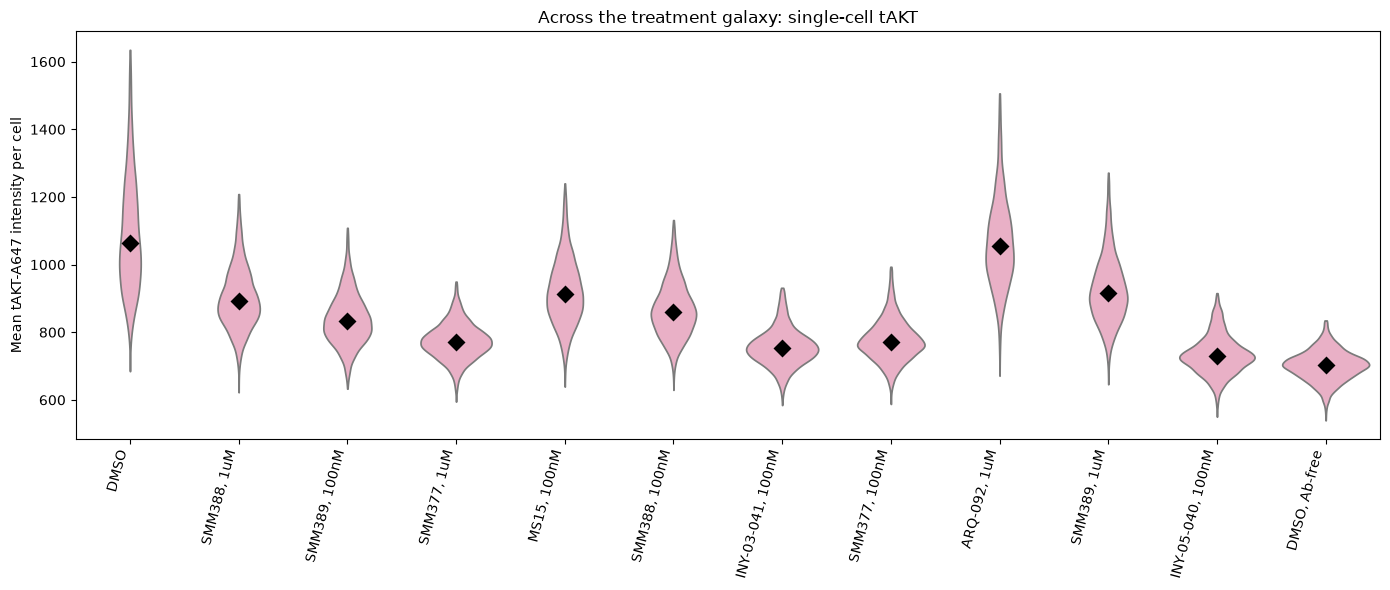

In [ ]:
treatment_order = list(dict.fromkeys(analysis_data["treatment"].dropna()))
plt.figure(figsize=(14, 6))
sns.violinplot(
    data=analysis_data,
    x="treatment",
    y="tAKT_mean_intensity",
    order=treatment_order,
    inner=None,
    color="#f3a6c4",  # tAKT stays magenta
    cut=0,
)
sns.pointplot(
    data=analysis_data,
    x="treatment",
    y="tAKT_mean_intensity",
    order=treatment_order,
    estimator="median",
    errorbar=None,
    color="black",
    markers="D",
    linestyle="none",
)
plt.xticks(rotation=75, ha="right")
plot_title = (
    "Across the treatment galaxy: single-cell tAKT"
    if STAR_WARS_MODE
    else "Single-cell tAKT intensity after QC"
)
plt.title(plot_title)
plt.xlabel("")
plt.ylabel("Mean tAKT-A647 intensity per cell")
plt.tight_layout()
plt.show()

## How did we decide which cells are G1, S or G2/M?

Hoechst intensity is a DNA-content proxy. In a simple cycling population:

- **G1** cells contain roughly one genome's worth of DNA;
- **S-phase** cells are copying DNA, so they lie between the G1 and G2/M peaks;
- **G2/M** cells have roughly twice the G1 DNA content before division.

This does **not** mean that one bright nucleus can be classified confidently by
eye. Focus, staining, segmentation and nuclear size also affect integrated
intensity. We classify cells from the population distribution.

The code below follows four steps:

1. Use DMSO controls to estimate the dominant G1 Hoechst peak separately for
   each experiment. This accommodates experiment-to-experiment intensity shifts.
2. Restrict the peak search to the lower 70% of controls so the G2/M peak cannot
   accidentally become the reference.
3. Divide every nucleus by its experiment's G1 peak. A G1-like nucleus is then
   near 1 and a G2/M-like nucleus is near 2.
4. Apply the starting gates used in the analysis: `<1.25` for G1, `1.25–1.75`
   for S and `≥1.75` for G2/M.

The density plot remains the essential check. The dashed gates should fall
between the DNA-content peaks. Never accept a gate only because the code ran.

### Why the phases may not look obviously different

The phase label is based on **total Hoechst signal inside the nuclear mask**,
not on StarDist recognising a G1-, S- or G2/M-shaped nucleus. A nucleus can
have more integrated Hoechst because it is brighter, larger, or both. The
difference can therefore be quantitative without being visually dramatic.
Hoechst also cannot reliably separate G2 from mitosis because both contain
approximately 4N DNA, so they remain one **G2/M** category.

The example images below all use one shared raw-pixel intensity scale taken
from the complete Hoechst field. Matplotlib is not allowed to rescale each
nucleus independently, and the shared colour bar reports the original pixel
values. This makes brightness comparable across the three panels.

### What might one nucleus from each phase look like?

These are representative nuclei from the **real DMSO teaching field**, selected
by integrated Hoechst ratio. They illustrate the expected trend, not a visual
classifier: G2/M tends to contain more total Hoechst signal than G1, while S lies
between them.

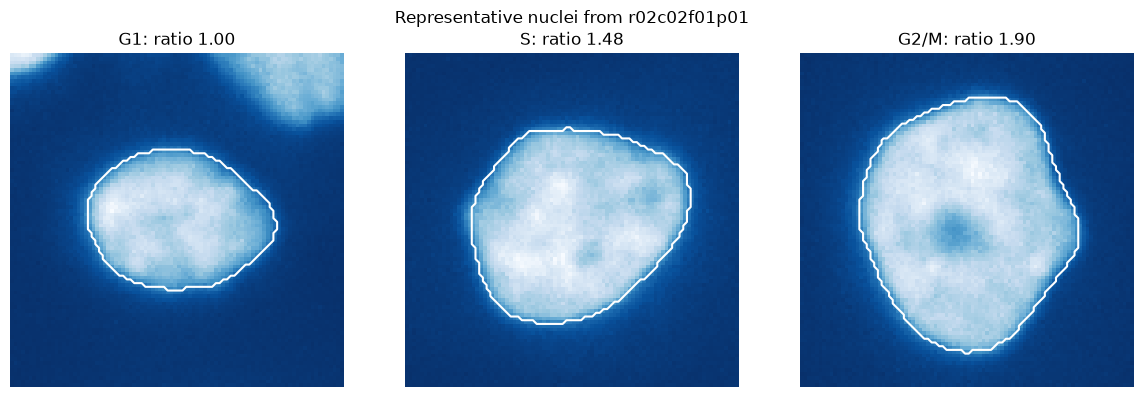

In [ ]:
teaching_nuclear_mask = supplied_nuclear_mask
teaching_nuclei = pd.DataFrame(regionprops_table(
    teaching_nuclear_mask,
    intensity_image=hoechst,
    properties=("label", "area", "centroid", "mean_intensity"),
)).rename(columns={
    "label": "nucleus_ID",
    "centroid-1": "centroid_X",
    "centroid-0": "centroid_Y",
    "mean_intensity": "Hoechst_mean_intensity",
})
teaching_nuclei["Hoechst_integrated_intensity"] = (
    teaching_nuclei["area"] * teaching_nuclei["Hoechst_mean_intensity"]
)

# For this teaching field, the median of the lower half approximates the G1 peak
lower_half = teaching_nuclei.nsmallest(
    max(3, len(teaching_nuclei) // 2), "Hoechst_integrated_intensity"
)
teaching_g1_peak = lower_half["Hoechst_integrated_intensity"].median()
teaching_nuclei["Hoechst_ratio"] = (
    teaching_nuclei["Hoechst_integrated_intensity"] / teaching_g1_peak
)
teaching_nuclei["phase"] = pd.cut(
    teaching_nuclei["Hoechst_ratio"],
    bins=[-np.inf, 1.25, 1.75, np.inf],
    labels=["G1", "S", "G2/M"],
    right=False,
)

phase_targets = {"G1": 1.0, "S": 1.5, "G2/M": 1.9}
# Use one raw-intensity scale for every panel; do not autoscale each crop.
shared_vmin = float(np.min(hoechst))
shared_vmax = float(np.max(hoechst))
fig, axes = plt.subplots(1, 3, figsize=(12, 4), constrained_layout=True)

for ax, (phase, target_ratio) in zip(axes, phase_targets.items()):
    candidates = teaching_nuclei.loc[teaching_nuclei["phase"].eq(phase)].copy()
    chosen = candidates.loc[(candidates["Hoechst_ratio"] - target_ratio).abs().idxmin()]
    x, y = int(round(chosen["centroid_X"])), int(round(chosen["centroid_Y"]))
    radius = 45
    y0, y1 = max(0, y - radius), min(hoechst.shape[0], y + radius)
    x0, x1 = max(0, x - radius), min(hoechst.shape[1], x + radius)

    image_patch = hoechst[y0:y1, x0:x1]
    mask_patch = teaching_nuclear_mask[y0:y1, x0:x1] == chosen["nucleus_ID"]
    image_artist = ax.imshow(
        image_patch,
        cmap="Blues_r",
        vmin=shared_vmin,
        vmax=shared_vmax,
    )
    ax.contour(mask_patch, levels=[0.5], colors="white", linewidths=1.5)
    ax.set_title(f"{phase}: ratio {chosen['Hoechst_ratio']:.2f}")
    ax.axis("off")

fig.colorbar(
    image_artist,
    ax=axes,
    label="Raw Hoechst pixel intensity (shared scale)",
    shrink=0.82,
)
fig.suptitle(f"Representative nuclei from {FIELD_NAME}")
plt.show()

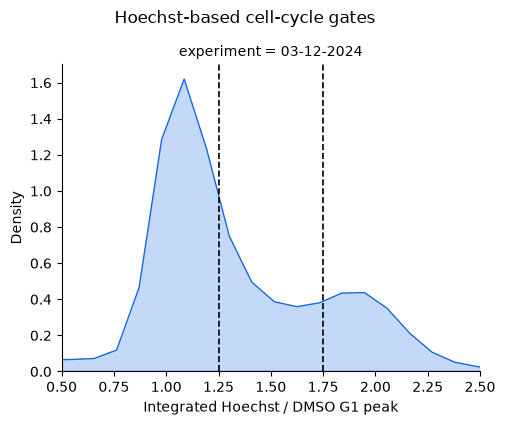

cell_cycle_from_gates
G1      40113
S       16632
G2/M    14752
Name: count, dtype: int64


In [ ]:
# Create the columns available in the old combined dataset
gated_data = analysis_data.copy()

gated_data["experiment"] = "03-12-2024"

# Proxy for integrated Hoechst because the real CSVs contain mean intensity
gated_data["Hoechst_integrated_intensity"] = (
    gated_data["Hoechst_mean_intensity"] * gated_data["area"]
)

gated_data = gated_data.dropna(
    subset=["Hoechst_integrated_intensity"]
).copy()

gated_data["Hoechst_ratio"] = np.nan

for experiment, rows in gated_data.groupby("experiment"):
    controls = rows.loc[
        rows["treatment"].astype(str).eq("DMSO"),
        "Hoechst_integrated_intensity",
    ]

    if controls.empty:
        controls = rows.loc[
            rows["treatment"].astype(str).str.startswith("DMSO"),
            "Hoechst_integrated_intensity",
        ]

    if controls.empty:
        raise ValueError(f"No DMSO controls found for {experiment}")

    # Restrict the search so the G2/M peak cannot win.
    g1_search = controls.loc[
        controls <= controls.quantile(0.70)
    ]

    counts, edges = np.histogram(g1_search, bins=60)
    peak_index = counts.argmax()
    g1_peak = (
        edges[peak_index] + edges[peak_index + 1]
    ) / 2

    gated_data.loc[rows.index, "Hoechst_ratio"] = (
        rows["Hoechst_integrated_intensity"] / g1_peak
    )

gated_data["cell_cycle_from_gates"] = pd.cut(
    gated_data["Hoechst_ratio"],
    bins=[-np.inf, 1.25, 1.75, np.inf],
    labels=["G1", "S", "G2/M"],
    right=False,
)

grid = sns.displot(
    data=gated_data,
    x="Hoechst_ratio",
    col="experiment",
    kind="kde",
    fill=True,
    color="#1769e0",
    height=4,
    aspect=1.25,
    facet_kws={"sharey": False},
)

for axis in grid.axes.flat:
    axis.axvline(1.25, color="black", linestyle="--", linewidth=1.2)
    axis.axvline(1.75, color="black", linestyle="--", linewidth=1.2)
    axis.set_xlim(0.5, 2.5)

grid.set_axis_labels(
    "Integrated Hoechst / DMSO G1 peak",
    "Density",
)
grid.fig.suptitle("Hoechst-based cell-cycle gates", y=1.05)

plt.show()

print(
    gated_data["cell_cycle_from_gates"]
    .value_counts()
    .reindex(["G1", "S", "G2/M"])
)

## Is the tAKT result independent of cell cycle?

A separate box plot for each phase shows the distributions, but it makes the
main question surprisingly hard to answer. A more direct test is the paper-style
stratification below:

- x-axis: depletion using all cells
- y-axis: depletion using only one cell-cycle phase
- dashed diagonal: exactly the same conclusion in both analyses

Points close to the diagonal suggest the treatment ranking is not simply caused
by a shift in cell-cycle composition.

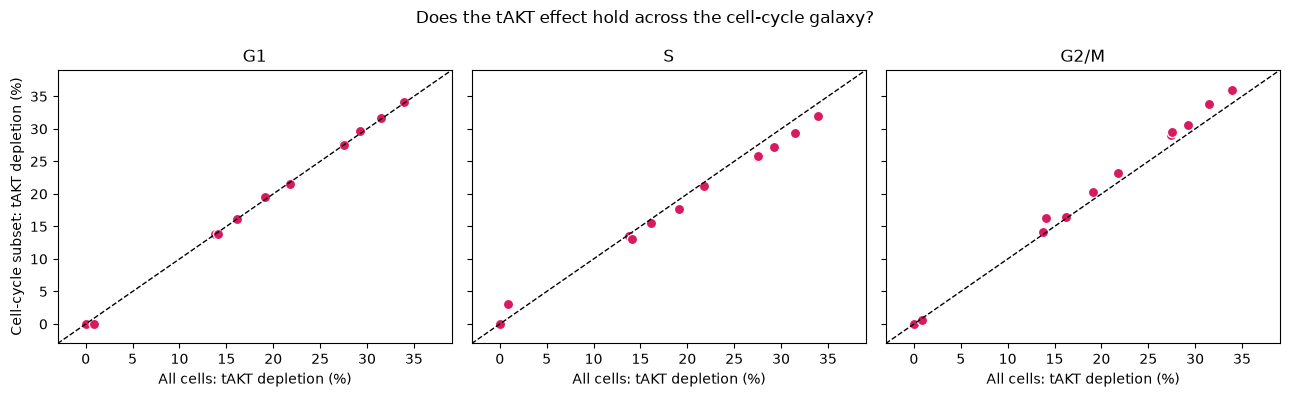

In [ ]:
if "cell_cycle_from_gates" in gated_data.columns:
    cycle_order = ["G1", "S", "G2/M"]
    control_name = "DMSO"

    overall_medians = gated_data.groupby("treatment", observed=True)["tAKT_mean_intensity"].median()
    overall_reference = overall_medians.loc[control_name]
    overall_depletion = (100 * (1 - overall_medians / overall_reference)).rename(
        "all_cells_depletion"
    )

    phase_medians = (
        gated_data.groupby(["cell_cycle_from_gates", "treatment"], observed=True)
        ["tAKT_mean_intensity"]
        .median()
        .rename("phase_median")
        .reset_index()
    )
    phase_references = (
        phase_medians.loc[phase_medians["treatment"].eq(control_name)]
        .set_index("cell_cycle_from_gates")["phase_median"]
    )
    phase_medians["phase_depletion"] = phase_medians.apply(
        lambda row: 100 * (
            1 - row["phase_median"] / phase_references.loc[row["cell_cycle_from_gates"]]
        ),
        axis=1,
    )
    comparison = phase_medians.join(overall_depletion, on="treatment")

    fig, axes = plt.subplots(1, 3, figsize=(13, 4), sharex=True, sharey=True)
    limits = [
        min(comparison["all_cells_depletion"].min(), comparison["phase_depletion"].min()) - 3,
        max(comparison["all_cells_depletion"].max(), comparison["phase_depletion"].max()) + 3,
    ]
    for axis, phase in zip(axes, cycle_order):
        subset = comparison.loc[comparison["cell_cycle_from_gates"].eq(phase)]
        axis.plot(limits, limits, color="black", linestyle="--", linewidth=1)
        axis.scatter(
            subset["all_cells_depletion"],
            subset["phase_depletion"],
            color="#d81b60",  # tAKT stays magenta
            edgecolor="white",
            s=55,
        )
        axis.set_title(phase)
        axis.set_xlim(limits)
        axis.set_ylim(limits)
        axis.set_xlabel("All cells: tAKT depletion (%)")
    axes[0].set_ylabel("Cell-cycle subset: tAKT depletion (%)")
    fig.suptitle(
        "Does the tAKT effect hold across the cell-cycle galaxy?"
        if STAR_WARS_MODE
        else "Cell-cycle stratification of tAKT depletion"
    )
    plt.tight_layout()
    plt.show()
else:
    print("Cell-cycle gates are unavailable; skip this optional section.")

# We made it!!! Yay

You have just followed the real pipeline:

1. viewed three matched microscopy channels;
2. inspected a supplied whole-cell mask;
3. measured original tAKT pixels inside cells;
4. reproduced Cellpose and StarDist segmentation on a crop;
5. measured integrated nuclear Hoechst;
6. matched cells and nuclei one-to-one;
7. applied the production area and intensity filters;
8. compared treatments using the full processed experiment.